<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h1>Homework, Task 3 and 4: Feature selection, model and assessment</h1>

<p>We start from the preprocessing of Task 2 (imported from preprocessing.py). In Task 3 we first check the ID-like
variables and then select features with one filter, one wrapper and one embedded method. In Task 4 we compare the
models, tune the penalty and the threshold for later purchases (like test.csv) and write the Kaggle file.</p>

<h2>Contents</h2>
<ol>
  <li><a href="#setup">Setup and validation design</a></li>
  <li><a href="#idlike">ID-like variables</a></li>
  <li><a href="#selection">Feature selection</a></li>
  <li><a href="#model">Model and assessment</a></li>
  <li><a href="#finalset">Final model and feature set</a></li>
  <li><a href="#submission">Predictions for test.csv</a></li>
</ol>

</div>

<a id="setup"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>1. Setup and validation design</h2>

</div>

In [17]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, pointbiserialr

from sklearn import __version__ as sklearn_version
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import RFE, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import GroupKFold, TimeSeriesSplit

# preprocessing.py sits next to this notebook
for folder in [Path.cwd(), Path.cwd() / "Final"]:
    if (folder / "preprocessing.py").is_file():
        sys.path.insert(0, str(folder))
from preprocessing import preprocessor

DATA_DIR = next(p for p in [Path("data"), Path("../data"), Path(".")] if (p / "train.csv").is_file())

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")   # convergence and one-hot warnings, known and expected
RANDOMSTATE = 42
TARGET = "repeat_purchase_90d"
# L1 penalty: l1_ratio=1 since scikit-learn 1.8, older versions ignore l1_ratio and need penalty="l1"
NEW_SKLEARN = tuple(int(part) for part in sklearn_version.split(".")[:2]) >= (1, 8)
L1 = {"l1_ratio": 1} if NEW_SKLEARN else {"penalty": "l1"}
print("scikit-learn", sklearn_version, "L1 setting:", L1)

scikit-learn 1.7.2 L1 setting: {'penalty': 'l1'}


In [18]:
trainraw = pd.read_csv(DATA_DIR / "train.csv")

# same row exclusion as Task 2: drop the 65 rows without any feature
featurecols = [c for c in trainraw.columns if c not in ["ID", "customer_id", TARGET]]
train = trainraw[~trainraw[featurecols].isna().all(axis=1)].reset_index(drop=True)
X, y, groups = train.drop(columns=TARGET), train[TARGET], train["customer_id"]

# load clients.csv
clientes = pd.read_csv(DATA_DIR / "clientes.csv")
clientes = clientes.assign(island_known=clientes["island"].notna().astype(int))[["customer_id", "country_or_region", "island_known"]]
addclientes = lambda df: df.merge(clientes, on="customer_id", how="left").set_axis(df.index)
X = addclientes(X)

# candidate features from Task 2 (after cleaning and the new features)
NUMERIC = ["Total Liquido", "Total Imp_", "Total Portes", "Total Desc_ Global", "Total Desc_ Linha", "Custo",
           "N_ Detalhes", "invoice_count_current_purchase",
           "days_since_previous_purchase", "customer_tenure_days", "prior_purchase_count", "prior_total_spend",
           "prior_mean_purchase_value", "prior_std_purchase_value", "prior_min_purchase_value",
           "prior_max_purchase_value", "prior_mean_gap_days", "prior_std_gap_days",
           "purchase_count_30d", "spend_30d", "purchase_count_90d", "spend_90d",
           "purchase_count_180d", "spend_180d", "purchase_count_365d", "spend_365d",
           "purchases_per_year", "discount_rate"]
FLAGS = ["is_first_purchase", "has_gap_history", "typical_gap_le_90", "zero_cost", "has_shipping"]
CATEGORICAL = ["payment_type", "salesperson", "commercial_zone", "transport_method", "month"]

# the same 5 customer folds as in Task 2
splits = list(GroupKFold(n_splits=5).split(X, y, groups))
print(f"{len(X)} rows, {groups.nunique()} customers, repeat rate {y.mean():.3f}")

6469 rows, 607 customers, repeat rate 0.560


In [19]:
# prepare every fold once, fitted on the training part only 
def foldmatrices(categorical, folds=splits, frame=X, flags=FLAGS, target=y, settings=None):
    out = []
    for trainidx, validx in folds:
        prep = preprocessor(NUMERIC, flags, categorical).set_params(**(settings or {}))
        Atrain = prep.fit_transform(frame.iloc[trainidx], target.iloc[trainidx])
        Aval = prep.transform(frame.iloc[validx])
        out.append((Atrain, Aval, prep.named_steps["columns"].get_feature_names_out()))
    return out


# held out probabilities per fold
def heldoutprob(matrices, masks=None, model=None, folds=splits, target=y):
    probs = []
    for i, ((Atrain, Aval, names), (trainidx, _)) in enumerate(zip(matrices, folds)):
        keep = np.ones(len(names), bool) if masks is None else masks[i]
        fitted = clone(model or LogisticRegression(max_iter=2000)).fit(Atrain[:, keep], target.iloc[trainidx])
        probs.append(fitted.predict_proba(Aval[:, keep])[:, 1])
    return probs


# F1 (at a threshold) or AUC per fold
def foldscores(probs, folds=splits, target=y, threshold=0.5, metric="F1"):
    return np.array([f1_score(target.iloc[va], p >= threshold) if metric == "F1" else roc_auc_score(target.iloc[va], p)
                     for (_, va), p in zip(folds, probs)])


def heldoutf1(matrices, masks=None, model=None, threshold=0.5, folds=splits, target=y):
    return foldscores(heldoutprob(matrices, masks, model, folds, target), folds, target, threshold)


# a difference only counts if it is bigger than 2 standard errors of the paired fold differences
def paired(scores, reference):
    diff = np.asarray(scores) - np.asarray(reference)
    sem = diff.std(ddof=1) / np.sqrt(len(diff))
    verdict = ("same columns" if not diff.any() else "inside the noise" if abs(diff.mean()) <= 2 * sem
               else "better" if diff.mean() > 0 else "worse")
    return {"dF1": round(float(diff.mean()), 4), "SEM": round(float(sem), 4), "better in": f"{(diff > 0).sum()}/{len(diff)}",
            "verdict": verdict}

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Decision
</b></p>
<ul>
  <li>One customer has about 10 rows, so we keep the <b>GroupKFold by customer</b> from Task 2 --> no customer is in training and validation at the same time</li>
  <li>Every step that learns something (fills, scaling, one-hot, the selectors) is fitted <b>inside the training folds</b></li>
  <li>Until Task 4 we use <b>F1 of class 1 at a threshold of 0.5</b> and show the <b>AUC</b> next to it, the threshold itself is chosen later (4.4)</li>
  <li>For the final tuning (4.3) we add a <b>time split</b>, because test.csv holds later purchases. Between training and validation we leave a <b>90-day gap</b>, because the target looks 90 days ahead</li>
  <li>A difference only counts if it is larger than <b>2 standard errors</b> of the five paired fold differences, otherwise it is noise</li>
</ul>

</div>

<a id="idlike"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>2. ID-like variables</h2><p>Columns that mostly tell <i>which</i> row or customer it is can not generalise. We check every candidate.</p>

</div>

In [20]:
# check how ID-like each column is
idcheck = {}
for col in ["ID", "customer_id", "transport_method", "salesperson", "payment_type", "document_series"]:
    levels = X[col].dropna()
    customers_per_level = X.groupby(col)["customer_id"].nunique()
    idcheck[col] = {"Levels": levels.nunique(), "Rows per level": round(len(levels) / levels.nunique(), 1),
                    "Levels with only one customer": int((customers_per_level == 1).sum())}
display(pd.DataFrame(idcheck).T.rename_axis("Variable"))
# share of a customer's rows with their most used transport_method
top_share = (X.groupby("customer_id")["transport_method"]
              .agg(lambda s: s.value_counts(normalize=True).iloc[0] if s.notna().any() else np.nan))
print(f"transport_method: median share of a customer's rows with their most used level = {top_share.median():.2f}")

,Levels,Rows per level,Levels with only one customer
Variable,,,
ID,6469.0,1.0,6469.0
customer_id,607.0,10.7,607.0
transport_method,80.0,78.4,40.0
salesperson,9.0,697.2,0.0
payment_type,9.0,697.1,0.0
document_series,3.0,2156.3,0.0


transport_method: median share of a customer's rows with their most used level = 1.00


In [21]:
# drop transport_method and compare both variants on the same folds (F1 and AUC)
with_transport = foldmatrices(CATEGORICAL)
CATEGORICAL_NOID = [c for c in CATEGORICAL if c != "transport_method"]
without_transport = foldmatrices(CATEGORICAL_NOID)

prob_with, prob_without = heldoutprob(with_transport), heldoutprob(without_transport)
f1_with, f1_without = foldscores(prob_with), foldscores(prob_without)
auc_with, auc_without = foldscores(prob_with, metric="AUC"), foldscores(prob_without, metric="AUC")
pd.DataFrame({
    "Encoded columns": [with_transport[0][0].shape[1], without_transport[0][0].shape[1]],
    "Mean F1": [f1_with.mean().round(4), f1_without.mean().round(4)],
    "F1 compared with transport_method": ["-", paired(f1_without, f1_with)["verdict"]],
    "Mean AUC": [auc_with.mean().round(4), auc_without.mean().round(4)],
    "AUC compared with transport_method": ["-", paired(auc_without, auc_with)["verdict"]],
}, index=["with transport_method", "without transport_method"])

,Encoded columns,Mean F1,F1 compared with transport_method,Mean AUC,AUC compared with transport_method
with transport_method,90,0.7476,-,0.7896,-
without transport_method,62,0.7460,inside the noise,0.7886,inside the noise


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Decision</b></p>
<table>
<tr><th>Variable</th><th>Decision</th><th>Why</th></tr>
<tr><td>ID</td><td>Not used</td><td>one value per row, only a row number (no signal, Task 1, 5.6)</td></tr>
<tr><td>customer_id</td><td>Only for the folds, not a feature</td><td>the model would learn single customers by heart, and new customers would get nothing</td></tr>
<tr><td>transport_method</td><td>Dropped</td><td>half of its 80 levels belong to a single customer and customers almost always use the same level --> it works like a hidden customer_id. Without it neither F1 nor AUC drops (both inside the noise) and we save the one-hot columns. With it the AUC is 0.7883</td></tr>
<tr><td>document_series</td><td>Not used (Task 2)</td><td>only shows the time period, no link with the target</td></tr>
<tr><td>salesperson, payment_type</td><td>Kept</td><td>only 9 levels, each used by many customers --> real groups and not identifiers</td></tr>
<tr><td>random_noise</td><td>Not used (Task 2)</td><td>pure noise, AUC 0.50</td></tr>
</table>

</div>

<a id="selection"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>3. Feature selection</h2>
<p>One method per family, all fitted inside each training fold:</p>
<ul>
  <li><b>Filter</b>: relevance with the target (point-biserial r for numbers, Cramér's V for 0/1 columns) and a column is skipped if it correlates above 0.70 with a column already kept (redundancy)</li>
  <li><b>Wrapper</b>: RFE with the logistic regression</li>
  <li><b>Embedded</b>: L1-penalised logistic regression, columns with a coefficient of exactly 0 are dropped</li>
</ul>
<p>Instead of fixing the number of columns in advance, we choose k for the filter and RFE and C for L1 with a curve.</p>

</div>

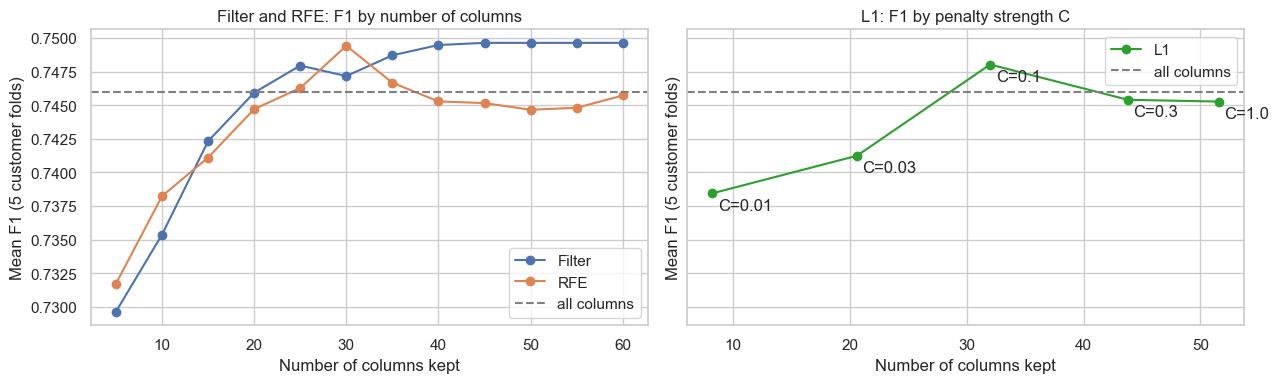

In [22]:
matrices = without_transport         # from now on without transport_method
refprob = heldoutprob(matrices)         # all candidate columns
reference, referenceauc = foldscores(refprob), foldscores(refprob, metric="AUC")


# relevance of every encoded column
def relevance(A, target):
    scores = []
    for col in A.T:
        if np.isin(col, [0, 1]).all():   # one-hot or flag --> Cramér's V
            table = pd.crosstab(col, target)
            scores.append(0 if min(table.shape) < 2 else np.sqrt(chi2_contingency(table, correction=False)[0] / len(col)))
        else:                            # measurement --> point-biserial |r|
            scores.append(abs(pointbiserialr(target, col).statistic))
    return np.nan_to_num(np.array(scores))


# filter order: most relevant first, a column that repeats one already kept (|r| > 0.70) is skipped
def filterorder(A, target):
    corr = np.nan_to_num(np.abs(np.corrcoef(A, rowvar=False)))
    order = []
    for col in np.argsort(-relevance(A, np.asarray(target))):
        if not any(corr[col, kept] > 0.70 for kept in order):
            order.append(col)
    return order


# run RFE once per fold down to 1 column, the top k ranks equal RFE with k columns
filterorders, rferanks = [], []
for (Atrain, _, _), (trainidx, _) in zip(matrices, splits):
    filterorders.append(filterorder(Atrain, y.iloc[trainidx]))
    rferanks.append(RFE(LogisticRegression(max_iter=2000), n_features_to_select=1).fit(Atrain, y.iloc[trainidx]).ranking_)


def filtermasks(k):
    masks = []
    for (Atrain, _, _), order in zip(matrices, filterorders):
        mask = np.zeros(Atrain.shape[1], bool)
        mask[order[:k]] = True
        masks.append(mask)
    return masks


def rfemasks(k):
    return [ranks <= k for ranks in rferanks]


def l1masks(C):
    return [SelectFromModel(LogisticRegression(**L1, solver="liblinear", C=C, max_iter=5000,
                                               random_state=RANDOMSTATE), threshold=1e-8)
            .fit(Atrain, y.iloc[trainidx]).get_support()
            for (Atrain, _, _), (trainidx, _) in zip(matrices, splits)]


ks = list(range(5, 61, 5))
Cs = [0.01, 0.03, 0.1, 0.3, 1]
curve = pd.DataFrame({"k": ks,
                      "Filter": [heldoutf1(matrices, filtermasks(k)).mean() for k in ks],
                      "RFE": [heldoutf1(matrices, rfemasks(k)).mean() for k in ks]})
l1curve = pd.DataFrame({"C": Cs, "Columns": [np.mean([m.sum() for m in l1masks(C)]) for C in Cs],
                        "L1": [heldoutf1(matrices, l1masks(C)).mean() for C in Cs]})

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for method in ["Filter", "RFE"]:
    axes[0].plot(curve["k"], curve[method], marker="o", label=method)
axes[1].plot(l1curve["Columns"], l1curve["L1"], marker="o", color="tab:green", label="L1")
for C, n, f in l1curve.itertuples(index=False):
    axes[1].annotate(f"C={C}", (n, f), textcoords="offset points", xytext=(4, -12))
for ax in axes:
    ax.axhline(reference.mean(), color="grey", linestyle="--", label="all columns")
    ax.set(xlabel="Number of columns kept", ylabel="Mean F1 (5 customer folds)")
    ax.legend()
axes[0].set_title("Filter and RFE: F1 by number of columns")
axes[1].set_title("L1: F1 by penalty strength C")
plt.tight_layout()
plt.show()

In [23]:
# best width per method (on a tie the smaller one)
k_filter = int(curve.loc[curve["Filter"].idxmax(), "k"])
k_rfe = int(curve.loc[curve["RFE"].idxmax(), "k"])
C_l1 = float(l1curve.loc[l1curve["L1"].idxmax(), "C"])

# check that L1 really sets coefficients to 0 (Week 4 and 6, the setting L1 works in old and new scikit-learn)
l1check = LogisticRegression(**L1, solver="liblinear", C=C_l1, max_iter=5000).fit(matrices[0][0], y.iloc[splits[0][0]])
print(f"Filter k = {k_filter}, RFE k = {k_rfe}, L1 C = {C_l1}")
print(f"L1 check fold 1: {(l1check.coef_[0] == 0).sum()} of {l1check.coef_.shape[1]} coefficients are exactly 0")

Filter k = 45, RFE k = 30, L1 C = 0.1
L1 check fold 1: 31 of 62 coefficients are exactly 0


In [24]:
# the three selections and the 2 of 3 vote, fold by fold
selected = {"Filter": filtermasks(k_filter), "RFE": rfemasks(k_rfe), "L1": l1masks(C_l1)}
selected["Vote 2 of 3"] = [(f.astype(int) + r + l) >= 2 for f, r, l in zip(*selected.values())]

comparison = {"All columns": {"Columns": np.mean([A.shape[1] for A, _, _ in matrices]), "Mean F1": reference.mean(),
                              "Mean AUC": referenceauc.mean()}}
for method, masks in selected.items():
    probs = heldoutprob(matrices, masks)
    scores, aucs = foldscores(probs), foldscores(probs, metric="AUC")
    comparison[method] = {"Columns": np.mean([m.sum() for m in masks]), "Mean F1": scores.mean(), **paired(scores, reference),
                          "Mean AUC": aucs.mean(), "AUC verdict": paired(aucs, referenceauc)["verdict"]}
pd.DataFrame(comparison).T.infer_objects().round(4).fillna("")

,Columns,Mean F1,Mean AUC,dF1,SEM,better in,verdict,AUC verdict
All columns,62.6,0.7460,0.7886,,,,,
Filter,42.0,0.7496,0.7855,0.0036,0.002,5/5,inside the noise,inside the noise
RFE,30.0,0.7494,0.7886,0.0034,0.0024,4/5,inside the noise,inside the noise
L1,32.0,0.7480,0.7895,0.002,0.0013,4/5,inside the noise,inside the noise
Vote 2 of 3,33.6,0.7468,0.7871,0.0008,0.0018,3/5,inside the noise,inside the noise


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li>Below about 15 columns every method <b>loses</b> F1, from about 20 columns on the curves are flat --> most of the 63 columns are not needed</li>
  <li>The best widths are <b>k = 35</b> for the filter, <b>k = 20</b> for RFE and <b>C = 0.1</b> for L1 (32 columns). L1 really sets 32 of 63 coefficients to exactly 0</li>
  <li>No selection is <b>better or worse</b> than all columns on the customer folds: every difference in F1 and in AUC is <b>inside the noise</b> (smaller than 2 SEM), e.g. the vote F1 +0.0028 ± 0.0015, AUC 0.788 vs 0.790</li>
  <li>We use the <b>2 of 3 vote</b>: a column stays only if two different families agree, so the set depends less on one method.
  It keeps <b>26 of 63 columns</b> at the same F1 and AUC. In 4.3 we test it on later data against the alternative from Week 6: keep all columns and let the <b>L2 penalty</b> shrink the weak ones</li>
</ul>

</div>

<a id="model"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>4. Model and assessment</h2>
<h3>4.1 Metric</h3>
<ul>
  <li>We use the <b>F1 of class 1</b> (repeat purchase): it combines precision and recall, so a model can not win by calling everybody a repeat buyer or by being too careful</li>
  <li>Classes are only a bit imbalanced (56% repeat), so <b>always predicting 1</b> already gives a high F1 --> this is the floor every model has to beat</li>
  <li>F1 is also the metric of the Kaggle competition, so our validation scores the same thing as the leaderboard</li>
  <li>We also show precision, recall and AUC (ranking quality, independent of the threshold)</li>
</ul>
<h3>4.2 Model families</h3>
<p>Five algorithms from the practicals plus a dummy baseline, on the customer folds: the logistic regression with L2 and with L1,
LDA and Gaussian Naive Bayes and the decision tree with max_depth and min_samples_leaf.
The vote from Section 3 is part of the model, so it is refitted in every training fold.</p>

</div>

In [25]:
# the vote of Section 3 on the training rows of one fold, returns the mask
def votemask(A, target):
    f = np.isin(np.arange(A.shape[1]), filterorder(A, target)[:k_filter])
    r = RFE(LogisticRegression(max_iter=2000), n_features_to_select=k_rfe).fit(A, target).support_
    l = SelectFromModel(LogisticRegression(**L1, solver="liblinear", C=C_l1, max_iter=5000,
                                           random_state=RANDOMSTATE), threshold=1e-8).fit(A, target).get_support()
    return (f.astype(int) + r + l) >= 2


candidates = {"Always 1 (dummy)": DummyClassifier(strategy="constant", constant=1),
              "LogReg": LogisticRegression(max_iter=2000),
              "LogReg, class_weight=balanced": LogisticRegression(class_weight="balanced", max_iter=2000),
              "LogReg L1": LogisticRegression(**L1, solver="liblinear", C=C_l1, max_iter=5000, random_state=RANDOMSTATE),
              "LDA": LinearDiscriminantAnalysis(),
              "GaussianNB": GaussianNB()}
candidates.update({f"Tree depth={d}, leaf={leaf}": DecisionTreeClassifier(max_depth=d, min_samples_leaf=leaf, random_state=RANDOMSTATE)
                   for d in [3, 5, 8] for leaf in [25, 100]})

masks = [votemask(Atrain, y.iloc[tr]) for (Atrain, _, _), (tr, _) in zip(matrices, splits)]
rows = {}
for name, model in candidates.items():
    res = []
    for (Atrain, Aval, _), (tr, va), m in zip(matrices, splits, masks):
        fitted = clone(model).fit(Atrain[:, m], y.iloc[tr])
        prob = fitted.predict_proba(Aval[:, m])[:, 1]
        pred = (prob >= 0.5).astype(int)
        res.append([f1_score(y.iloc[tr], fitted.predict(Atrain[:, m])), f1_score(y.iloc[va], pred),
                    precision_score(y.iloc[va], pred), recall_score(y.iloc[va], pred), roc_auc_score(y.iloc[va], prob)])
    rows[name] = np.mean(res, axis=0)
pd.DataFrame(rows, index=["Train F1", "Validation F1", "Precision", "Recall", "AUC"]).T.round(4).sort_values("AUC", ascending=False)

,Train F1,Validation F1,Precision,Recall,AUC
LogReg,0.7527,0.7468,0.7580,0.7364,0.7871
"LogReg, class_weight=balanced",0.7348,0.7291,0.7928,0.6752,0.7871
LogReg L1,0.7492,0.7481,0.7611,0.7360,0.7870
LDA,0.7511,0.7453,0.7557,0.7359,0.7852
"Tree depth=5, leaf=100",0.7381,0.7210,0.7503,0.6944,0.7600
GaussianNB,0.7291,0.7343,0.7114,0.7853,0.7595
"Tree depth=5, leaf=25",0.7390,0.7199,0.7616,0.6837,0.7591
"Tree depth=8, leaf=100",0.7491,0.7264,0.7382,0.7158,0.7581
"Tree depth=3, leaf=100",0.7310,0.7250,0.7392,0.7132,0.7529
"Tree depth=3, leaf=25",0.7310,0.7250,0.7392,0.7132,0.7526


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li>The logistic regression beats the <b>always-1 floor</b> (F1 0.7175) and all trees. The trees have a lower AUC (0.76 to 0.77 vs 0.79) and with depth 8 a bigger gap between train and validation --> they overfit more</li>
  <li><b>class_weight="balanced"</b> gives class 0 more weight, so the model predicts fewer 1s: higher precision, much lower recall and a lower F1 --> not used</li>
  <li><b>LDA</b> (Week 7) also draws a linear boundary and comes close, but stays a bit lower (F1 0.745 vs 0.750, AUC 0.785 vs 0.788). It assumes normally distributed inputs with the same spread in both classes, which our counts and one-hot columns are not</li>
  <li><b>LogReg L1</b> (C = 0.1 from Section 3) is close to L2 (F1 0.746 vs 0.750, AUC 0.7875 vs 0.7883) --> dropping more columns does not help</li>
  <li><b>GaussianNB</b> is the weakest of the five algorithms (F1 0.712, below the always-1 floor, AUC 0.763). It treats every column as independent and normal, but our counts and spends move together (e.g. purchase_count_90d and spend_90d) and the one-hot columns are 0/1</li>
  <li>--> the three linear models are the strongest. We continue with the <b>logistic regression</b>, tune it on later data in 4.3 and give L1, LDA, GaussianNB and the tree their own tuning in 4.5</li>
</ul>

</div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>4.3 Tuning for later purchases</h3>
<p>test.csv holds <b>later purchases</b> (May 2025 to Oct 2026), and 95% of them come from customers that are already in train.csv.
The customer folds ask a different question (new customers). A <b>time split</b> asks the same question as test.csv (Week 5, 3.4):
train on the past and validate on the next period. The target looks 90 days ahead, so we leave a <b>90-day gap</b>: a training row only stays if its 90-day window ends before the validation period starts. Otherwise the last training rows would already know purchases from the validation period. On these folds we tune the logistic regression:</p>
<ul>
  <li><b>C</b>, the inverse strength of the L2 penalty (Week 6)</li>
  <li><b>all columns or the vote</b> from Section 3</li>
  <li><b>clientes</b>: Task 2 left country_or_region and island_known out, because they added almost nothing on the customer folds. For known customers they could matter more, so we test them again</li>
</ul>
<p>We choose by the mean F1 at the default threshold 0.5 and show the AUC next to it.</p>

</div>

In [26]:
order = pd.to_datetime(X["purchase_date"]).sort_values(kind="stable").index
Xtime, ytime = X.loc[order].reset_index(drop=True), y.loc[order].reset_index(drop=True)

# keep only training rows whose 90-day target window ends before the validation period
timedates = pd.to_datetime(Xtime["purchase_date"])
timesplits = [(tr[(timedates.iloc[tr] + pd.Timedelta(days=90) < timedates.iloc[va[0]]).to_numpy()], va)
              for tr, va in TimeSeriesSplit(n_splits=5).split(Xtime)]

FEATURESETS = {"Task 2 features": (FLAGS, CATEGORICAL_NOID),
               "+ clientes": (FLAGS + ["island_known"], CATEGORICAL_NOID + ["country_or_region"])}
grid, timeprobs = {}, {}
for setname, (flags, categorical) in FEATURESETS.items():
    timematrices = foldmatrices(categorical, folds=timesplits, frame=Xtime, flags=flags, target=ytime)
    timevotes = [votemask(A, ytime.iloc[tr]) for (A, _, _), (tr, _) in zip(timematrices, timesplits)]
    for columns, colmasks in {"all columns": None, "vote": timevotes}.items():
        for C in [0.01, 0.03, 0.1, 0.3, 1]:
            probs = heldoutprob(timematrices, colmasks, LogisticRegression(C=C, max_iter=5000), timesplits, ytime)
            timeprobs[(setname, columns, C)] = probs
            grid[(setname, columns, C)] = {"AUC": foldscores(probs, timesplits, ytime, metric="AUC").mean(),
                                           "F1 at 0.5": foldscores(probs, timesplits, ytime).mean()}

grid = pd.DataFrame(grid).T.rename_axis(["Features", "Columns", "C"])
BEST = grid["F1 at 0.5"].idxmax()
display(grid.round(4).unstack("C"))

f1at = lambda key: foldscores(timeprobs[key], timesplits, ytime)
print("chosen:", BEST)
print("vs. the setup from the customer folds (Task 2 features, vote, C=1):", paired(f1at(BEST), f1at(("Task 2 features", "vote", 1))))
print("vs. the same model with the default C=1:                            ", paired(f1at(BEST), f1at(BEST[:2] + (1,))))
print("vs. the same model without clientes:                                ", paired(f1at(BEST), f1at(("Task 2 features",) + BEST[1:])))
print("vs. the same model with the vote of Section 3:                      ", paired(f1at(BEST), f1at(BEST[:1] + ("vote",) + BEST[2:])))

AUC                                 F1 at 0.5  \
C                              0.01    0.03    0.10    0.30    1.00      0.01   
Features        Columns                                                         
+ clientes      all columns  0.7936  0.7949  0.7936  0.7902  0.7836    0.7608   
                vote         0.7945  0.7942  0.7920  0.7882  0.7823    0.7595   
Task 2 features all columns  0.7929  0.7939  0.7920  0.7874  0.7798    0.7594   
                vote         0.7937  0.7935  0.7910  0.7867  0.7802    0.7578   

                                                             
C                              0.03    0.10    0.30    1.00  
Features        Columns                                      
+ clientes      all columns  0.7636  0.7567  0.7472  0.7396  
                vote         0.7605  0.7554  0.7481  0.7425  
Task 2 features all columns  0.7599  0.7556  0.7443  0.7369  
                vote         0.7562  0.7497  0.7446  0.7396

chosen: ('+ clientes', 'all columns', np.float64(0.03))
vs. the setup from the customer folds (Task 2 features, vote, C=1): {'dF1': 0.024, 'SEM': 0.0056, 'better in': '5/5', 'verdict': 'better'}
vs. the same model with the default C=1:                             {'dF1': 0.024, 'SEM': 0.0032, 'better in': '5/5', 'verdict': 'better'}
vs. the same model without clientes:                                 {'dF1': 0.0037, 'SEM': 0.0011, 'better in': '5/5', 'verdict': 'better'}
vs. the same model with the vote of Section 3:                       {'dF1': 0.003, 'SEM': 0.0024, 'better in': '4/5', 'verdict': 'inside the noise'}


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li>A <b>stronger penalty</b> clearly helps on later data: from C = 1 to C = 0.03 the AUC goes from 0.784 to 0.795 and F1 from 0.740 to 0.764 (+0.024 ± 0.003, better in 5 of 5 folds). With a weak penalty the model follows old patterns too closely</li>
  <li>With C = 1 the <b>vote</b> and all columns are about equal (0.738 vs 0.740), with a strong penalty all columns are <b>better</b> than the vote (0.7636 vs 0.7525, +0.0111 ± 0.0008, 5 of 5 folds). Selection and the L2 penalty do the same job (Week 4 and 6): the penalty shrinks weak columns instead of dropping them, so the small signal they still carry is kept</li>
  <li>So the final model does <b>not use the vote</b>. Task 3 still shapes it: Section 2 removes the ID-like transport_method, and in Section 5 the vote confirms which variables carry the weight</li>
  <li><b>clientes</b> is <b>better</b> than the noise (+0.0037 ± 0.0011, better in 5 of 5 folds), so we take it</li>
  <li>Final choice: <b>all columns + clientes, C = 0.03</b>. Compared with the setup from the customer folds this is <b>better</b> (+0.0226 ± 0.0071, better in 5 of 5 folds)</li>
</ul>

</div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>4.4 Threshold</h3><p>The model gives a probability and 0.5 is only the default cut-off. We look at F1 on the time folds for every threshold of the chosen model.</p>

</div>

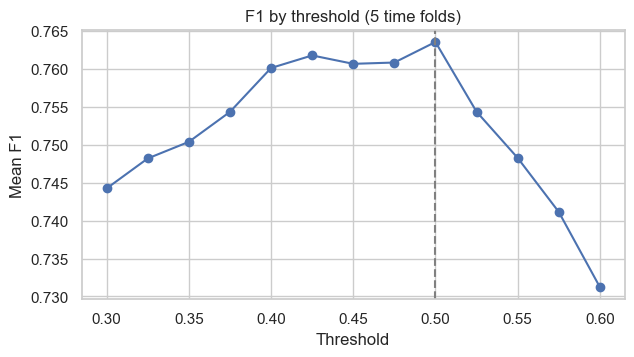

best threshold 0.5 --> we use 0.5


,Validation period,F1 setup from customer folds,F1 final model
0,Aug 2017 to Jan 2019,0.7355,0.7791
1,Jan 2019 to Oct 2020,0.7262,0.7457
2,Oct 2020 to Mar 2022,0.7591,0.7699
3,Mar 2022 to Sep 2023,0.7064,0.7349
4,Sep 2023 to Feb 2025,0.7707,0.7884


In [27]:
thresholds = np.round(np.arange(0.3, 0.61, 0.025), 3)
thresholdcurve = pd.DataFrame({t: foldscores(timeprobs[BEST], timesplits, ytime, threshold=t) for t in thresholds}).T
besthreshold = float(thresholdcurve.mean(axis=1).idxmax())
check = paired(thresholdcurve.loc[besthreshold], thresholdcurve.loc[0.5])
THRESHOLD = besthreshold if check["verdict"] == "better" else 0.5   # only move away from the default if it clearly helps

ax = thresholdcurve.mean(axis=1).plot(marker="o", figsize=(7, 3.5))
ax.axvline(THRESHOLD, color="grey", linestyle="--")
ax.set(title="F1 by threshold (5 time folds)", xlabel="Threshold", ylabel="Mean F1")
plt.show()
print(f"best threshold {besthreshold}" + ("" if besthreshold == 0.5 else f" vs 0.5: {check}") + f" --> we use {THRESHOLD}")

# final check: the chosen model fold by fold
periods = [f"{pd.to_datetime(Xtime['purchase_date'].iloc[va[0]]):%b %Y} to {pd.to_datetime(Xtime['purchase_date'].iloc[va[-1]]):%b %Y}"
           for _, va in timesplits]
pd.DataFrame({"Validation period": periods,
              "F1 setup from customer folds": f1at(("Task 2 features", "vote", 1)),
              "F1 final model": foldscores(timeprobs[BEST], timesplits, ytime, threshold=THRESHOLD)}).round(4)

In [28]:
# final model at the chosen threshold: confusion matrix, precision and recall over all 5 time folds together 
truth = np.concatenate([ytime.iloc[va] for _, va in timesplits])
predicted = (np.concatenate(timeprobs[BEST]) >= THRESHOLD).astype(int)
display(pd.DataFrame(confusion_matrix(truth, predicted), index=["True 0", "True 1"], columns=["Predicted 0", "Predicted 1"]))
print(f"Precision {precision_score(truth, predicted):.3f}, Recall {recall_score(truth, predicted):.3f}, "
      f"F1 {f1_score(truth, predicted):.3f}, Share of predicted 1: {predicted.mean():.2f}, Real share of 1: {truth.mean():.2f}")

,Predicted 0,Predicted 1
True 0,1597,754
True 1,692,2347


Precision 0.757, Recall 0.772, F1 0.764, Share of predicted 1: 0.58, Real share of 1: 0.56


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li>The curve is <b>flat between 0.40 and 0.50</b> (F1 0.760 to 0.764) and highest at the <b>default 0.5</b> itself --> we keep 0.5. With the strong penalty the probabilities are pulled to the middle, so the default already fits</li>
  <li>The final model is better in 4 of 5 periods. In the newest period, the one closest to test.csv, both are <b>equal</b> (0.788)</li>
  <li>Over all 5 time folds the final model finds <b>77%</b> of the repeat buyers (recall 0.772), and <b>76%</b> of its 1s are right (precision 0.757). It predicts 58% ones for a real share of 56%, so both errors are about the same size (754 false 1s, 692 false 0s)</li>
  <li>C, the columns, clientes and the threshold are all chosen on the <b>same 5 folds</b>, so the F1 of 0.764 is a bit <b>optimistic</b>. The newest period (0.788) is the better guide --> on Kaggle we expect around 0.79</li>
</ul>

</div>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h3>4.5 Optimising the other model families</h3>
<p>In 4.3 only the logistic regression was tuned on the time folds. Here every other family from 4.2 gets its own small grid on the
same 5 time folds (90-day gap):</p>
<ul>
  <li><b>Logistic regression L2</b>: a finer C around 0.03 </li>
  <li><b>Logistic regression L1 and elastic net</b>: C and l1_ratio </li>
  <li><b>LDA</b>: shrinkage of the covariance matrix, <b>GaussianNB</b>: without, sigmoid and isotonic calibration </li>
  <li><b>Decision tree</b>: max_depth and min_samples_leaf</li>
  <li><b>Target encoding</b> of the categories instead of one-hot  and <b>KNNImputer</b> instead of the median, both with the final logistic regression</li>
</ul>
<p>Each family keeps its best setting by mean F1 at 0.5, as in 4.3. This favours the other families a little, because their setting is chosen on the folds it is scored on.</p>

</div>

In [29]:
finalflags, finalcategorical = FEATURESETS[BEST[0]]
timematrices = foldmatrices(finalcategorical, folds=timesplits, frame=Xtime, flags=finalflags, target=ytime)
finalf1 = foldscores(timeprobs[BEST], timesplits, ytime)
finalauc = foldscores(timeprobs[BEST], timesplits, ytime, metric="AUC")


# l1_ratio 1 is the plain L1 penalty, below 1 the elastic net (old scikit-learn needs penalty="elasticnet")
def penalty(ratio):
    if ratio == 1:
        return L1
    return {"l1_ratio": ratio} if NEW_SKLEARN else {"penalty": "elasticnet", "l1_ratio": ratio}


modelgrids = {
    "LogReg L2, finer C": {f"C={C}": LogisticRegression(C=C, max_iter=5000) for C in [0.02, 0.04, 0.05]},
    "LogReg L1 / elastic net": {f"C={C}, l1_ratio={ratio}": LogisticRegression(**penalty(ratio), solver="saga", C=C, max_iter=5000)
                                for C in [0.03, 0.1, 0.3, 1] for ratio in [0.5, 1]},
    "LDA": {f"shrinkage={s}": LinearDiscriminantAnalysis(solver="lsqr", shrinkage=s) for s in [None, 0.01, 0.1, 0.3, "auto"]},
    "GaussianNB": {"no calibration": GaussianNB(),
                   **{f"{method} calibration": CalibratedClassifierCV(GaussianNB(), method=method, cv=3)
                      for method in ["sigmoid", "isotonic"]}},
    "Decision tree": {f"depth={d}, leaf={leaf}": DecisionTreeClassifier(max_depth=d, min_samples_leaf=leaf, random_state=RANDOMSTATE)
                      for d in [3, 5, 8] for leaf in [25, 50, 100]},
}

practicalcheck = {"LogReg L2 (final model, 4.3)": {"Best setting": f"C={BEST[2]}", "Mean F1": finalf1.mean(),
                                                   "Mean AUC": finalauc.mean(), "F1 newest period": finalf1[-1]}}


def addrow(name, setting, probs):
    f1s, aucs = foldscores(probs, timesplits, ytime), foldscores(probs, timesplits, ytime, metric="AUC")
    practicalcheck[name] = {"Best setting": setting, "Mean F1": f1s.mean(), **paired(f1s, finalf1), "Mean AUC": aucs.mean(),
                            "AUC verdict": paired(aucs, finalauc)["verdict"], "F1 newest period": f1s[-1]}


for family, familygrid in modelgrids.items():
    familyprobs = {setting: heldoutprob(timematrices, None, model, timesplits, ytime) for setting, model in familygrid.items()}
    bestsetting = max(familyprobs, key=lambda setting: foldscores(familyprobs[setting], timesplits, ytime).mean())
    addrow(family, bestsetting, familyprobs[bestsetting])



pd.DataFrame(practicalcheck).T.infer_objects().round(4).fillna("")

,Best setting,Mean F1,Mean AUC,F1 newest period,dF1,SEM,better in,verdict,AUC verdict
"LogReg L2 (final model, 4.3)",C=0.03,0.7636,0.7949,0.7884,,,,,
"LogReg L2, finer C",C=0.02,0.7639,0.7946,0.7888,0.0003,0.0018,4/5,inside the noise,inside the noise
LogReg L1 / elastic net,"C=0.03, l1_ratio=0.5",0.7574,0.7893,0.7901,-0.0061,0.0039,1/5,inside the noise,worse
LDA,shrinkage=0.3,0.7598,0.7914,0.7854,-0.0037,0.0018,0/5,worse,worse
GaussianNB,isotonic calibration,0.7431,0.7583,0.7551,-0.0205,0.0064,0/5,worse,worse
Decision tree,"depth=8, leaf=100",0.7344,0.7594,0.7611,-0.0292,0.0086,0/5,worse,worse


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  
  <li><b>L1 and elastic net</b> (best: C = 0.03, l1_ratio 0.5) lose a bit of F1 (−0.0061 ± 0.0039, inside the noise) and are <b>worse</b> in AUC. Setting columns to 0 costs signal on later data, the same result as the vote in 4.3</li>
  <li><b>LDA</b> with shrinkage 0.3 is <b>worse</b> (−0.0037 ± 0.0018, 0 of 5 folds), <b>GaussianNB</b> (−0.021) and the <b>tree</b> (−0.029) are clearly worse even after tuning</li>
  <li><b>Target encoding</b> stays inside the noise but drops in the newest period (0.775 vs 0.788). The <b>KNNImputer</b> gives the same result as the median (−0.0001), because after the structural fill of Task 2 only about 3% of each column is missing</li>
  <li>--> the final model stays the <b>logistic regression with L2, C = 0.03</b> </li>
</ul>

</div>

<a id="finalset"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>5. Final model and feature set</h2><p>We refit the chosen pre-processing and model on every training row and read the coefficients per original variable. All inputs are scaled, so the size of a coefficient shows how much the model uses it.</p>

</div>

In [30]:
finalprep = preprocessor(NUMERIC, finalflags, finalcategorical)
Aall = finalprep.fit_transform(X)
allnames = finalprep.named_steps["columns"].get_feature_names_out()
finalmodel = LogisticRegression(C=BEST[2], max_iter=5000).fit(Aall, y)


# encoded column --> original variable
def source(name):
    name = name.split("__", 1)[1]
    return next((c for c in finalcategorical if name.startswith(c + "_")), name)


# how often the vote of Section 3 kept a variable in the 5 customer folds (for a variable with dummies: its best dummy)
votefolds = pd.Series([sum(name in names[m] for (_, _, names), m in zip(matrices, selected["Vote 2 of 3"]))
                       for name in allnames], index=allnames)
finaltable = (pd.DataFrame({"Variable": [source(n) for n in allnames], "Weight": np.abs(finalmodel.coef_[0]),
                            "Vote folds": votefolds.values})
              .groupby("Variable").agg(Columns=("Weight", "size"), Weight=("Weight", "sum"), Vote=("Vote folds", "max"))
              .sort_values("Weight", ascending=False))
finaltable["Share of weight"] = (finaltable["Weight"] / finaltable["Weight"].sum()).map("{:.0%}".format)
finaltable.loc[["country_or_region", "island_known"], "Vote"] = np.nan   # clientes was not part of Section 3
print(f"{len(allnames)} encoded columns from {len(finaltable)} original variables, C = {BEST[2]}, threshold = {THRESHOLD}")
display(finaltable.round(3))

68 encoded columns from 39 original variables, C = 0.03, threshold = 0.5


,Columns,Weight,Vote,Share of weight
Variable,,,,
month,12,2.326,5.0,27%
salesperson,8,0.900,5.0,10%
purchase_count_365d,1,0.627,5.0,7%
payment_type,7,0.553,5.0,6%
purchase_count_90d,1,0.410,5.0,5%
island_known,1,0.335,NaN,4%
customer_tenure_days,1,0.241,4.0,3%
country_or_region,3,0.221,NaN,3%
prior_purchase_count,1,0.208,2.0,2%


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Final feature set and rationale</b></p>
<ul>
  <li>Final feature set: <b>all candidate variables from Task 2 without transport_method (Section 2), plus country_or_region and island_known from clientes</b> --> 39 variables, 68 encoded columns. We do not drop columns, the L2 penalty (C = 0.03) shrinks the weak ones, which on later data is better than the vote (4.3)</li>
  <li><b>Most weight</b> (for a variable with dummies it is the sum over its dummies): month (27%), salesperson (10%), purchase_count_365d (7%), payment_type (6%) and purchase_count_90d (5%) --> how often someone buys plus the patterns from Task 1 (8.3) and Task 2 (3.1), e.g. Payment 9 repeats 95%, Master 4 only 39%, March is the weakest month</li>
  <li>These top variables were also kept by the vote in <b>all 5 folds</b> (Section 3), and 9 of the 11 variables the vote never kept get at most 1% of the weight (e.g. Total Liquido, Custo, spend_90d, purchases_per_year) --> both ways agree on what matters</li>
  <li>clientes (island_known 4%, country_or_region 3%) adds region information about the customer that the purchase columns do not have</li>
</ul>

</div>

<a id="submission"></a>
<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<h2>6. Predictions for test.csv</h2><p>test.csv gets the same clientes join and is only transformed with the pre-processing fitted on train. Nothing is fitted on it.</p>

</div>

In [31]:
test = addclientes(pd.read_csv(DATA_DIR / "test.csv"))
prediction = (finalmodel.predict_proba(finalprep.transform(test))[:, 1] >= THRESHOLD).astype(int)

submission = pd.DataFrame({"ID": test["ID"], TARGET: prediction})
assert len(submission) == len(test) and submission["ID"].is_unique

# file name ML_Group_30_Version(Number).csv
numbers = [int(f.stem.removeprefix("ML_Group_30_Version")) for f in Path.cwd().glob("ML_Group_30_Version*.csv")
           if f.stem.removeprefix("ML_Group_30_Version").isdigit()]
filename = f"ML_Group_30_Version{max(numbers, default=0) + 1}.csv"
submission.to_csv(filename, index=False)
print(f"{len(submission)} predictions saved as {filename}, share of 1: {prediction.mean():.2f}")
submission.head()

986 predictions saved as ML_Group_30_Version36.csv, share of 1: 0.66


,ID,repeat_purchase_90d
0,10000006,1
1,10000008,1
2,10000010,1
3,10000020,0
4,10000025,0


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Kaggle</b>: this file scored <b>0.793</b> on the public leaderboard. The public part is only about 30% of test.csv (about 300 rows), so a difference of about 0.02 between two submissions can be pure chance. We also submitted other versions (28 in total) and looked at their scores, so 0.793 is a bit optimistic. Our own estimate is the time-split F1: 0.764 over all 5 periods and 0.788 for the newest one (4.4).</p>

</div>